<a href="https://colab.research.google.com/github/tomviolin/FreshwateRWebSite/blob/main/r2u_ULTRA_FAST_PACKAGE_LOADING.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **FreshwateR UNIT TWO: Data Wrangling**

**IMPORTANT PLEASE READ:** All course content for the balance of UNIT TWO is in this notebook.  I recommend you simply scroll down this very long page and run the example codes with the "Play" button as you encounter them.  Alternatively, you can select above to- "Run all" and all the examples will run in order, and then you could potentially print the page as PDF and read it like a textbook where all the examples are already run and the output displayed.

## **r2u fast R package loading in Colab**

This cell ***MUST*** be run first or the rest of the examples may fail.  

In general you should run all the examples in order.  That's the way this notebook was written, and that's the way it has been tested.

###<font color="red">YOU ***MAY*** get a warning that **This notebook was not authored by Google**.  It's ok to respond affirmatively and go on.


In [218]:
# run this cell to get FAST loading with the install.packages(...) function.
install.packages <- function(pkgs, ...) {
  for (pkg in pkgs) {
    system(paste0("sudo apt-get install -y -q r-cran-", tolower(pkg)),
           ignore.stdout = TRUE, ignore.stderr = TRUE)
  }
}

# **Tidyverse**
### The ***tidyverse*** is a set of R functions that work together well and have some pretty clever ways of doing things.

Again, if you skip this one, things will not work down the page.

In [219]:
## Run the code in this cell to enable the Tidyverse in Colab.

install.packages("tidyverse")
library(tidyverse)

#**Data Wrangling!**
Now it's time to start ***data wrangling***.   This describes the process of examining and turning over your data, to gauge its size, range of values, and so on.

## **Obtain the data**

### **Gapminder** is a good example dataset, and obtaining it is easy, because it exists as an R installable package.

***Gapminder*** is an independent Swedish foundation with no political, religious, or economic affiliations. *__Gapminder__* identifies systematic misconceptions about important global trends and proportions and uses reliable data to develop easy to understand teaching materials to rid people of their misconceptions.



In [220]:
### run this cell to obtain the gapminder dataset

install.packages("gapminder")
library(gapminder)

## The actual "data wrangling" tools come in the form of individual little functions that do one little thing.  

It's when these little tools are combinbed and operate together that we see the power of this environment.  It might seem to start slow, but it's going to get pretty heavy pretty soon!

###**head()**
This shows the column headers, types, and the first few values in the dataset.

In [221]:
# run this cell to get column headers, types, and the first few values in the dataset.

head(gapminder)

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Afghanistan,Asia,1952,28.801,8425333,779.4453
Afghanistan,Asia,1957,30.332,9240934,820.8530
Afghanistan,Asia,1962,31.997,10267083,853.1007
Afghanistan,Asia,1967,34.020,11537966,836.1971
Afghanistan,Asia,1972,36.088,13079460,739.9811
Afghanistan,Asia,1977,38.438,14880372,786.1134


### Now that we have an overview of what the dataset looks like, we'll want to start looking around a bit.

##**filter()**
This applies a condition that each row of the dataset must satisfy for it to pass the filter.


In [222]:
# Applies a filter to the data frame.

filter(gapminder, year==2007)

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Afghanistan,Asia,2007,43.828,31889923,974.5803
Albania,Europe,2007,76.423,3600523,5937.0295
Algeria,Africa,2007,72.301,33333216,6223.3675
Angola,Africa,2007,42.731,12420476,4797.2313
Argentina,Americas,2007,75.320,40301927,12779.3796
Australia,Oceania,2007,81.235,20434176,34435.3674
Austria,Europe,2007,79.829,8199783,36126.4927
Bahrain,Asia,2007,75.635,708573,29796.0483
Bangladesh,Asia,2007,64.062,150448339,1391.2538


##**arrange()**
This sorts the data by one of the columns. Let's try it on the <b>year</b> column.

In [223]:
# now try sorting by year

arrange(gapminder, year)

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Afghanistan,Asia,1952,28.801,8425333,779.4453
Albania,Europe,1952,55.230,1282697,1601.0561
Algeria,Africa,1952,43.077,9279525,2449.0082
Angola,Africa,1952,30.015,4232095,3520.6103
Argentina,Americas,1952,62.485,17876956,5911.3151
Australia,Oceania,1952,69.120,8691212,10039.5956
Austria,Europe,1952,66.800,6927772,6137.0765
Bahrain,Asia,1952,50.939,120447,9867.0848
Bangladesh,Asia,1952,37.484,46886859,684.2442


# Combining data wranglers

This is ok, so far.  But notice how the fitered and arrange/sorted tables were very long to scroll through. Luckily, we have our **head()** function, so we can do this:

In [ ]:
head(filter(gapminder, year==2007))

In [ ]:
# and also this!

head(arrange(gapminder, year))

## **it worked, but...**

Ok so to filter and then look at the first few rows of that result, we had to do

```R
head(filter(gapminder, year==2007))
```

And to sort and then look at the first few rows, we had to do this:

```R
head(arrange(gapminder, year))
```

This approach is ok, but if things get much more complicated, we could be in trouble.

## **What if...**
What if we want to see the first few rows of all African nations sorted by population?  We'd have to:

- pick out just African nations by filtering for continent = 'Africa'
- arrange them sorted by population;
- then use head() to take the first few rows and show them.

This would like like this:

```R
head(arrange(filter(gapminder, continent=='Africa'),pop))
```


## **Not easy!**

In order to look at that line and figure out what to do, you'd need to you have to look from the ***innermost*** to ***outermost*** function calls.

head(arrange( **filter** **(** gapminder, continent=='Africa' **)**,pop))</span>

head(**arrange** **(** filter(gapminder, continent=='Africa'),pop **)** )

**head** **(** arrange(filter(gapminder, continent=='Africa'),pop) **)**
### **Confusing, isn't it? **
This is where the genius of **tidyverse** comes in.

Tidyverse introduces to R the concept of <B>THREADING</b> functions! There are two threading operators: **`%>%`** (percent-greater than sign-percent) and **`|>`** ( vertical bar-greater-than).  They allow you to "straighten out" your sequence of operations like this:

```R
head(arrange(filter(gapminder, continent=='Africa'),pop))
```

becomes

```R
gapminder |> filter(continent=='Africa`) |> arrange(pop) |> head()
```

##**Just a tad easier!**

In [224]:
head(arrange(filter(gapminder, continent=='Africa'),pop))

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Sao Tome and Principe,Africa,1952,46.471,60011,879.5836
Sao Tome and Principe,Africa,1957,48.945,61325,860.7369
Djibouti,Africa,1952,34.812,63149,2669.5295
Sao Tome and Principe,Africa,1962,51.893,65345,1071.5511
Sao Tome and Principe,Africa,1967,54.425,70787,1384.8406
Djibouti,Africa,1957,37.328,71851,2864.9691


##**So now we can do it like this:**

In [ ]:
gapminder |> filter(continent=='Africa') |> arrange(pop) |> head()

## **Same answer, much easier to follow code!**
It's almost like putting together Legos!

<img src="data:image/gif;base64,R0lGODlh9wDdAIABAAAAAP///yH+EUNyZWF0ZWQgd2l0aCBHSU1QACwAAAAA9wDdAAAC/oyPqcvt
D6OctNqLs968+w+G4kiW5omm6sq27gvH8kzX9o3n+s73/g8MCoclAICITNaMTGOn2VRKp04FMwPN
bo6G6/Rb5Da8EXK2ajlDweyP2BGFkA/ailptX7f3jzgc3ff293YnOHbHl8jgtwj4V2ZIdyY3h1Cp
uIL3SOloFdn42bgweXgp2YkZhljKiepp2uWaQPoaGmsbwJg6Ugib52upV4u7GoybK3t6vIvRmzwK
qDlY2QtKq6tRx+xRuEWK/TqrC35b3WwmvM3RzU2NdUlujBwvYa6+rh2eFvnMCt0vbtmEfPfe0Zu3
D9QFYgBPhUhX8BwwZQKRlapoMVDD/lyDfm2M+G+iMYDJDgarJ5KjRpQmQV5kOFLWQYiiKExcRmsY
RpcxNYpxRpChsJSQWlIE+pGnsqKukEqLmdMg0YVTlZaraPTpPH5WxviIanWYTaIEdbIEO0Nr2KtU
cdIM2Q/pPrUD6Vp9y9TnxrLyrNXVY/SqpsCJCP+bVhXv1nZ8M750urON4cPWCCueOsfZy4DsBCcF
M3kuGpP0hn4CylYn5Gh2MYX2mLmYYrg/ozpajQh3VSq72+JFPVazJ8Sdb68u+Dp4YxRo99oWWozZ
7C2eez9E9XnxrHPIkzONDoNf7+yH7k1/Ins2Wju0G5Kvue08+qD0sVmvvLxLIJvd/t+LhgecP7dI
1BokA/UXWTa/jZbdeq2URdJ9qXjnW4L/FagahiPBgeAL8uHT2Vg9EZgfHxSSSBKKJSqn4Ip7nFih
bt/I+CFnEmooGYwX0shjjz4aF6BrOsLmX1rV2bPVj0rUCIKDaxGYBJNuSPkkSlFK6M2QVdKxJJYt
FrnlKF16GWOYD12p5VlgmmkJmmk+aCGbw7n5Jn5xytmmFDiCWOeTd9Kwp1RkArGmS07yOSiLU8bW
p3QuxvhnW9cxyEWiHJr4KJEeFtoXoydEmkOg33GqHKOUmuqFp2FMmCmcoIqGEEKpOjHrEXGoSsKr
O4j6mK7BDZiRGQPWWilrvnYV/t+hcIZXxRWDaYFOsYSQKo55yhLHrLSxBiQrpcB+KwK1PICnprgs
AUtNs7Sqy25f4Zo77rU2HvtrrLN6Nmyt7k5Kbw+iyvuus8TWVsezJ/FC5RcAA8ybtgjz2nBKDINm
aXsT0/nMxXiKdVS/oV6W8MY2QgUvDnxpLPK8R1oLUasp24nkLte4/LJe5AoZZM0PN2oDZDozx/MS
Tv38adBp+Ux0Hmomi/R1a7lntAwD/6hbx3LNC2G0thjiVtclC4011VcnKbY0ZV89E8RBiFfczFOX
OLTVNAEGDNdYyz0Jyv5uli48CrUUdzUe90rysyHvCp0fZmt9duOOP06zDmQp/g555ZZfHvOYMWDO
eec5Hz351656TjrnN4RYy9FNHhlk6T72PI59FS9k6OWAkpNO1ElnCXrdWu/+w+wXjj448Nzc/mjk
xqtQ/Hc7Nr+85L7IjrvezUS/efXYnWx9GtgvUjT1TWXdfV0Kn/nOpw6NaHFORkOvyqTcFcHtUU0K
v53mAcOKMDTVkbg+nkyvZLup0wBv5qpysKBgQ2OgNmYUrf9RRILgKkquSoI64qUGaLZiVxTyti5p
dbBY9grhtz7YLmJtq4DmShsCR8Y60XGphILwGw3zRcJgtQtdOxSYw7aVl4AdQzgZKtyQTuPA+nWM
hyT0Id0IhkOH6KuCKxGi/td6hDcYmcKHFezbDWm4QyXqK4JTBKKBhPiX0nmDMmUE1xTfyLVORPCL
XFxhUjxmmReSTUbpa08XgXSrHj4xFiesoyHraEY5XPAzGKLa/DLkQMbhAYVPZM0SJ4gvSSjtYV/C
oCTHZqXTTauKidneTgYHpvW85TgHMhkUKZHIjlTLexecDziWEzdYupJJHzrcmGLnoM9R5nsL5Ncn
QUbEYRIzT7ywYtWMqEr8+amWzjRN41K3zIOFSxXkYyV4dBcRVJqgNaxcmXayOUM9ZSVzoMymDMOH
kQzGEJ3MpBikiCPNp5nJhcqj59o0ZTMX5TNl8INP+6BWNrOARJzZgmam/lxXTkwijpqbEmEuAwpR
JR00fs2UmkU1useMipSBSgxJrozk0LlZc6QsxaLa5PS6lLZ0QVj0ZwsyiNOLngt89JOaP+X5FZT+
tHwLLKhB0fnShobHphRc20AvZVOiZsKXjxwqVW8q1XowVTBI0CP6otrPbGW1D5IjFD67mjmnLeuc
IKqQQtpKmyiRbJxxMWEhDcJVKq7rraX64SWJUMOwVlFA0/JrvSzyuwA6bY72Q2sR+YXPMVbyo3ZF
rAcJlsvJNtFbUJGrnSArSzp662121M8G7bgGyY6wW6Z1o2A9FNlFCWV9ZRRkYGHCWC/qcIa+K+xT
xaojF9LWtoPc15xy/gukRDoJVUZ1QflIw1k4sq2kj2VsFLnV286qI6zQfWVt5Zhcg373tq41rBhf
69SQdVeBXyzhH0NhrNW+l4d7DO1Yv0Kz7gInkFPTJmdiGEmLNnWWeQWsoEr5zsMGL74JXt2BndNg
ES2YY4D9E46uiicM35Qx+t0qW4Wgq0OBc6G/TW88SqyUES94QR5W8Ypv2WIXv3gcMUZxhUm6VQ0X
k4NejZ6OMzHVpL5MxmsMciN392PmVdRxWQzmY+vpXCJnA7gzNV1IIydkAVZ5y48D3iS5DOaIEq1V
yvItZsNMIy8nOWKGa6fO0Lul+6aguRR255qZ41Ebs0zP6MmelFkV/uHj+TnQe/YscMHK5yfkmdBM
Y3SLDo1oOl9PsUVNdKMlDalE3/lpf76nkR0NaFB3ssGbDkupeVziU6fY0vdTdZJunEb4ddqWjXK1
/NI4Z1Yb04Ba0rWAuInpnfHaSyDkr2YhOMLcPdDYk7H1p8V1IrseUtpcnCMlcagt0noEZzqm6r1M
K10mivuGKtSheWMdaktdldrFDbdosz1aCArKUd3TIuXk6+58pzDe03XrpZOD4fDq22EDB6NeyePs
3r0m4MdWYMHfjW36xjKI4bwYw1NbbGYvRi7MHliBcV07hq17lL/GlKgHvc5ov5KvJj85yvWbyvwk
nHmzfvlNZn7pciq9EM5hwnm8GsPzOPv6Y2AJup9qvstlIz1HQ0ecTom5dKILE3tRl15av1d1q2c5
w1l3etPTHWy0fp3bLh/C2BUh50azl+rWHPNIZYrmm53d7QA6VZPR1nGgenjvc987mvwO+MDTXfDL
6zvhD494pYqgAAA7">

&nbsp;
[except that the code actually goes to the right and down, but I think the analogy is still good!!
&nbsp;

&nbsp;

## **More data wrangler tools**

In [ ]:
# Oh yeah, %>% and |> are equivalent. %>% is the "old way" and you will encounter it in older code
# written in R.  It's just as amazing, it just looks funny.

# sort in **descending** order of GDP per capita

gapminder %>% arrange(desc(gdpPercap))

In [ ]:
# generate new values or modify existing ones

# modify population to be by millions
gapminder %>% mutate( pop = pop / 1000000)

In [ ]:
# add a GDP column

gapminder %>% mutate( gdp = gdpPercap * pop )

#**AND NOW FOR SOMETHING COMPLETELY DIFFERENT!**
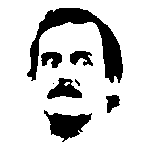

# **Just keeping you on your toes.**

## Two new wrangling functions that go together:

## **`group_by()`** and **`summarise()`**

###**In brief:**

**`group_by()`** creates a 'bin' for each unique value in the column you specify, and then **`summarise()`** sums, averages (mean, mode, median), takes the standard deviation of, computes the quantile of, (and other things) of any ***other*** columns besides the one(s) you have **`group`**-ed **`()`** by, and places those summaries  in each bin.

## **So for example:**

Let's say you have a table of values like this stored in an R dataframe called 'hunksofjunk':

***side note***: _I stepped away from the gapminder data for these few examples because the cars database is more accessible and is much smaller than the gapminder database, and it's much easier to know whether results you get actually make sense. The gapminder data does show up in the exercises._





In [225]:
# read in the hunks of junk!
hunksofjunk = read_csv('https://github.com/tomviolin/FreshwateR/raw/refs/heads/main/carnames2.csv')

Rows: 32 Columns: 13
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (2): make, model
dbl (11): mpg, cyl, disp, hp, drat, wt, qsec, vs, am, gear, carb

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [226]:
# what do we have here?
hunksofjunk |> head()

make,model,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Mazda,RX4,21.0,6,160,110,3.90,2.620,16.46,0,1,4,4
Mazda,RX4 Wag,21.0,6,160,110,3.90,2.875,17.02,0,1,4,4
Datsun,710,22.8,4,108,93,3.85,2.320,18.61,1,1,4,1
Hornet,4 Drive,21.4,6,258,110,3.08,3.215,19.44,1,0,3,1
Hornet,Sportabout,18.7,8,360,175,3.15,3.440,17.02,0,0,3,2
Dodge,Valiant,18.1,6,225,105,2.76,3.460,20.22,1,0,3,1


In [227]:
# Now let's see how many models each car (make) has in the list.
# NOTE: the use of n() to produce a count.  It's way better than having to include a column
# of all ones, just so you can sum them to get counts.  This really used to happen.

hunksofjunk |> group_by(make) |> summarise(car_count = n())

make,car_count
<chr>,<int>
AMC,1
Cadillac,1
Camaro,1
Chrysler,1
Datsun,1
Dodge,2
Duster,1
Ferrari,1
Fiat,2


In [228]:
#
# Ok! now lets get a ranking of how many models each make has:
hunksofjunk |> group_by(make) |> summarise(car_count = n()) |> arrange(car_count)

make,car_count
<chr>,<int>
AMC,1
Cadillac,1
Camaro,1
Chrysler,1
Datsun,1
Duster,1
Ferrari,1
Ford,1
Honda,1


In [229]:
#
# Although I think a ranking in DESCENDING order is usually more appealing:
hunksofjunk |>
  group_by(make) |>
    summarise(car_count = n()) |>
      arrange(desc(car_count)) |>
        head(10)

make,car_count
<chr>,<int>
Merc,7
Dodge,2
Fiat,2
Hornet,2
Mazda,2
Toyota,2
AMC,1
Cadillac,1
Camaro,1


In [ ]:
#
# and of course the ever-popular "top ten" list:
#
# NOTE: the use of the function row_number() to simply indicate which row number each row is.
# another thing that used to be kept around physically in the data before we are smart about
# these things.
hunksofjunk |>
  group_by(make) |>
    summarise(car_count = n()) |>
      arrange(desc(car_count)) |>
        head(10) |> mutate(rank=row_number()) |>
          relocate(rank)  #"relocate()" moves the named column to the first column position.

In [ ]:
#
# the top 3 gas guzzlers
hunksofjunk |>
      arrange(mpg) |>
        head(3) |> mutate(rank=row_number()) |>
          relocate(rank)  #"relocate()" moves the named column to the first column position.

In [ ]:
# average weight of car by number of cylinders
hunksofjunk |>
  group_by(cyl) |>
     summarise(avg_wt = mean(wt)) |>
      arrange(avg_wt) |>
        mutate(rank=row_number()) |>
          relocate(rank) #"relocate()" moves the named column to the first column position.

In [ ]:
#
# the 3 makes with the heaviest cars on average
hunksofjunk |>
    group_by(make) |>
      summarise(avg_wt = mean(wt)) |>
        arrange(desc(avg_wt)) |>
        head(3) |> mutate(rank=row_number()) |>
          relocate(rank)  #"relocate()" moves the named column to the first column position.

**Excercises** using the hunkofjunk dataset (use the above examples as close starting points).

- What are the top ten models of car in the list ranked by
- What Make has the highest gas mileage on average?

**Extra Credit**
Using the _gapminder_ data:
- list the GDP of every country in 2007.
- List the average life expectancy across the world, **weighted by population**, for each year for which there is data in the gapminder database.
